# Assignment 05: Sensor-Based Predictive Maintenance

## Aim
Use simulated machine/vehicle sensor readings to classify whether a component is operating normally or showing a failure condition.

## Sensor Variables
- Temperature
- Vibration
- Pressure
- RPM
- Operating hours

## Target Labels
- `0` → Healthy
- `1` → Failure

## Model
Random Forest Classifier

## Evaluation
Precision, recall, F1-score and the confusion matrix are used to examine classification performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
np.random.seed(17)

n = 820

temp = np.random.normal(
    75,
    10,
    n
)

vibration = np.random.normal(
    2.5,
    1.0,
    n
)

pressure = np.random.normal(
    30,
    5,
    n
)

rpm = np.random.normal(
    3000,
    400,
    n
)

run_hours = np.random.uniform(
    0,
    5000,
    n
)

failure_score = (
    0.04 * (temp - 75)
    + 0.8 * (vibration - 2.5)
    + 0.0006 * run_hours
    + np.random.normal(
        0,
        1,
        n
    )
)

failure = (
    failure_score > 1.2
).astype(int)

sensor_df = pd.DataFrame({
    "temperature_C": temp,
    "vibration_mm_s": vibration,
    "pressure_psi": pressure,
    "rpm": rpm,
    "run_hours": run_hours,
    "failure": failure
})

display(
    sensor_df.head()
)

,temperature_C,vibration_mm_s,pressure_psi,rpm,run_hours,failure
0,77.762659,1.579103,33.544061,3823.373037,871.132073,1
1,56.453719,3.594060,27.637599,3246.879505,3325.449080,1
2,81.239011,2.451558,35.579796,2880.669262,485.548150,0
3,86.453113,2.660698,25.057847,2666.504168,4266.813106,1
4,85.371905,2.064872,25.703993,3037.951520,981.698164,0


In [3]:
print(
    "Failure rate:",
    sensor_df["failure"].mean().round(3)
)

print(
    "\nClass distribution:"
)

print(
    sensor_df["failure"].value_counts()
)

Failure rate: 0.607

Class distribution:
failure
1    498
0    322
Name: count, dtype: int64


In [4]:
X = sensor_df.drop(
    columns=["failure"]
)

y = sensor_df["failure"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 615
Testing samples: 205


In [6]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(
    X_train
)

X_test_s = scaler.transform(
    X_test
)

In [7]:
clf = RandomForestClassifier(
    n_estimators=280,
    random_state=17,
    class_weight="balanced"
)

clf.fit(
    X_train_s,
    y_train
)

RandomForestClassifier(class_weight='balanced', n_estimators=280,
                       random_state=17)

In [8]:
preds = clf.predict(
    X_test_s
)

print(
    "Predictions generated successfully."
)

Predictions generated successfully.


In [9]:
print(
    classification_report(
        y_test,
        preds,
        target_names=[
            "Healthy",
            "Failure"
        ]
    )
)

              precision    recall  f1-score   support

     Healthy       0.68      0.65      0.67        80
     Failure       0.78      0.81      0.80       125

    accuracy                           0.75       205
   macro avg       0.73      0.73      0.73       205
weighted avg       0.74      0.75      0.75       205



Confusion Matrix:
[[ 52  28]
 [ 24 101]]


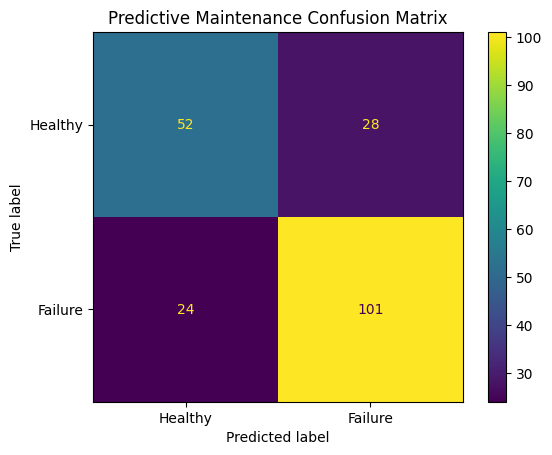

In [10]:
cm = confusion_matrix(
    y_test,
    preds
)

print(
    "Confusion Matrix:"
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Healthy",
        "Failure"
    ]
)

disp.plot()

plt.title(
    "Predictive Maintenance Confusion Matrix"
)

plt.show()

In [11]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": clf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(
    feature_importance
)

,Feature,Importance
4,run_hours,0.372614
1,vibration_mm_s,0.263477
0,temperature_C,0.154399
2,pressure_psi,0.105837
3,rpm,0.103673


## Result / Conclusion

A Random Forest model was trained to identify possible component failures from the simulated sensor readings.

Because failure and healthy observations are not necessarily equally represented, stratified splitting and balanced class weights were used. Precision, recall, F1-score and the confusion matrix then provide a more complete view of how well the model identifies the failure class.